In [81]:
!pip install xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [82]:
df= pd.read_csv('/content/Adult Census Income.csv')
df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [84]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [85]:
df.replace("?",np.nan,inplace=True)

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [87]:
df.duplicated().sum()

np.int64(24)

In [88]:
df.drop_duplicates()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [89]:
df.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0


In [90]:
cols=['workclass','occupation','native.country']
from sklearn.impute import SimpleImputer

for col in cols:
  imputer =SimpleImputer(strategy='most_frequent')
  df[[col]]=imputer.fit_transform(df[[col]])

In [91]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


In [92]:
df.reset_index(drop=True,inplace=True)

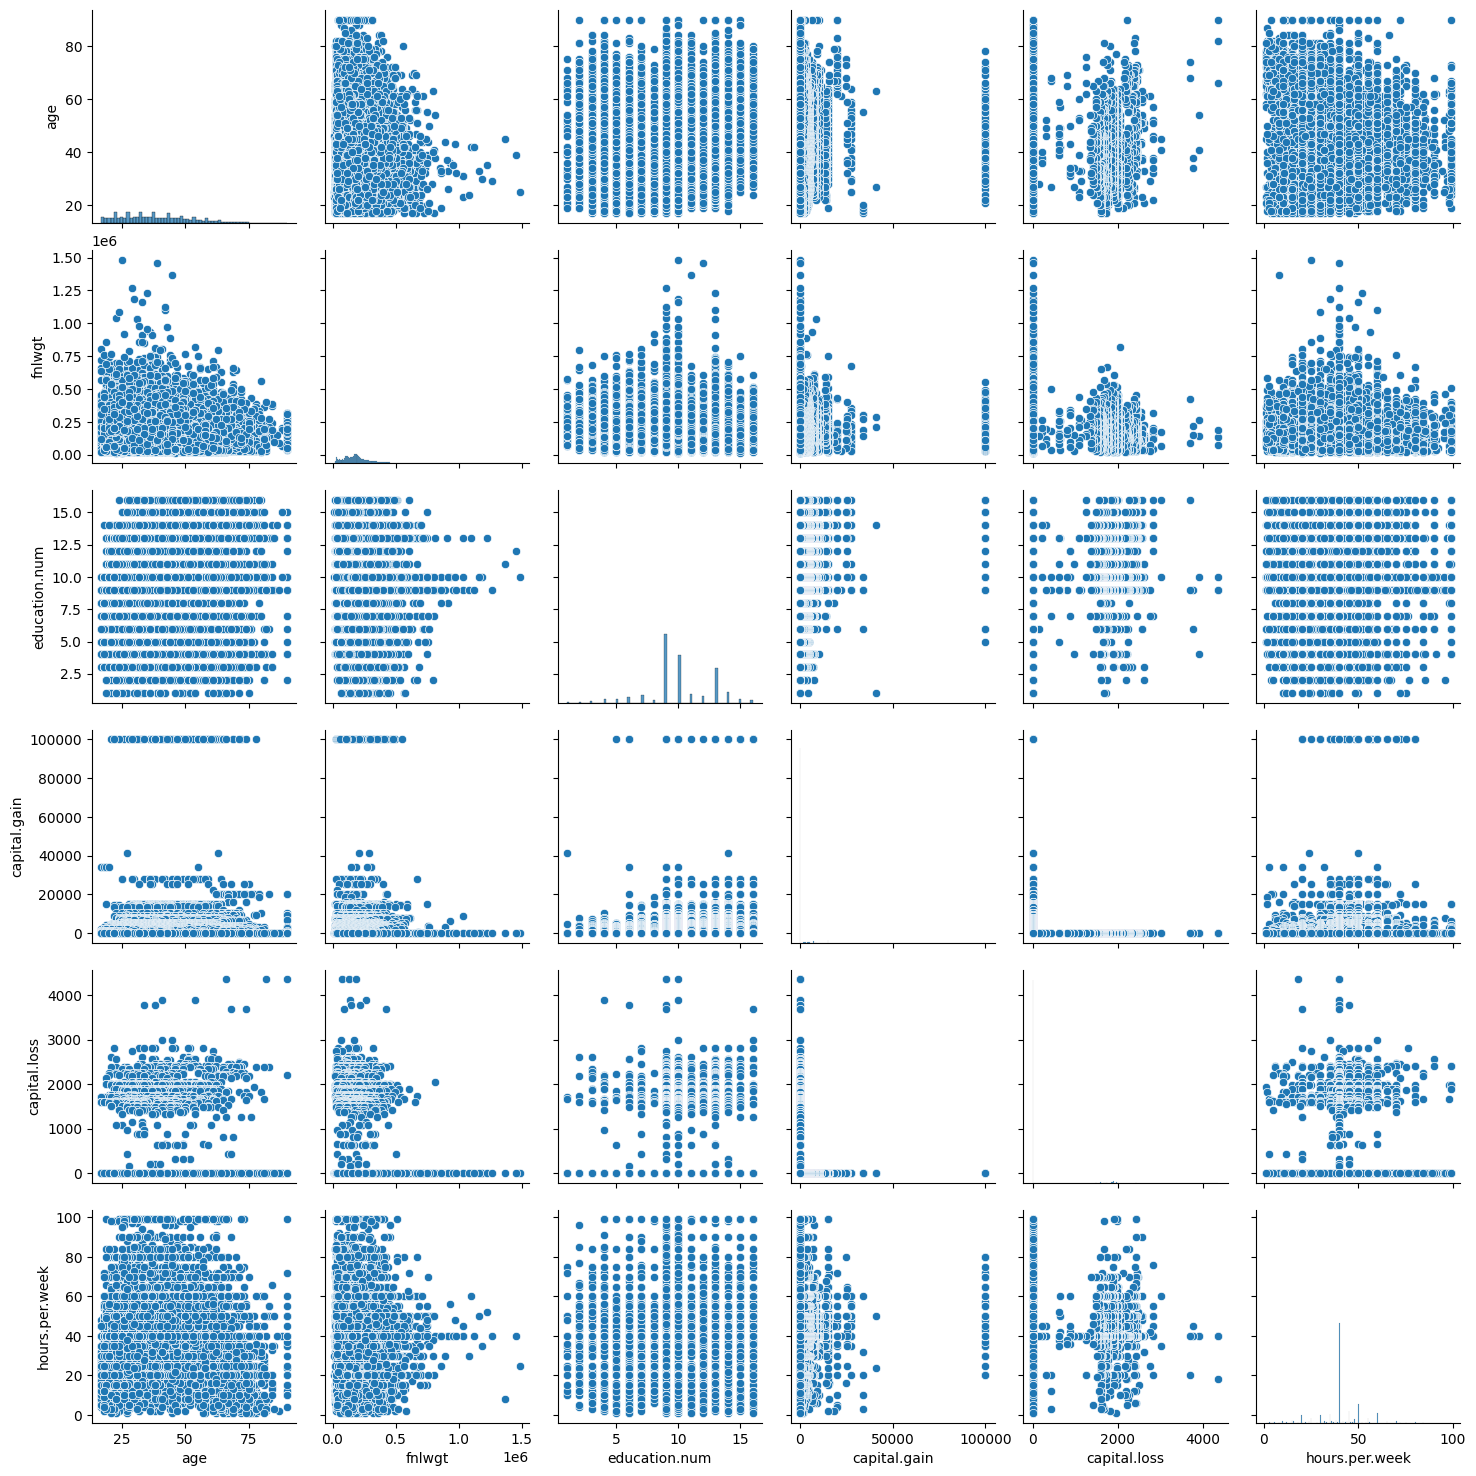

In [93]:
sns.pairplot(df)

<Axes: xlabel='occupation', ylabel='Count'>

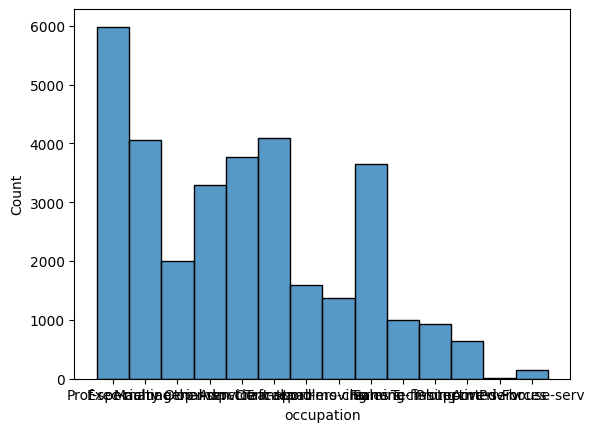

In [94]:
sns.histplot(df['occupation'])

<Axes: xlabel='count', ylabel='occupation'>

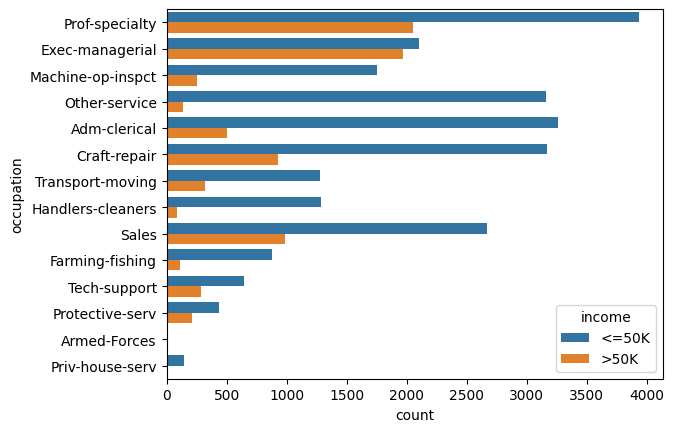

In [95]:
sns.countplot(data=df, y='occupation', hue='income')

<Axes: xlabel='count', ylabel='education'>

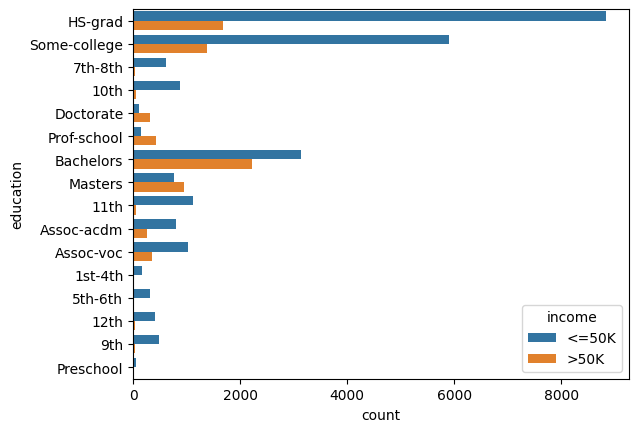

In [96]:
sns.countplot(data=df, y='education', hue='income')

<Axes: xlabel='sex', ylabel='count'>

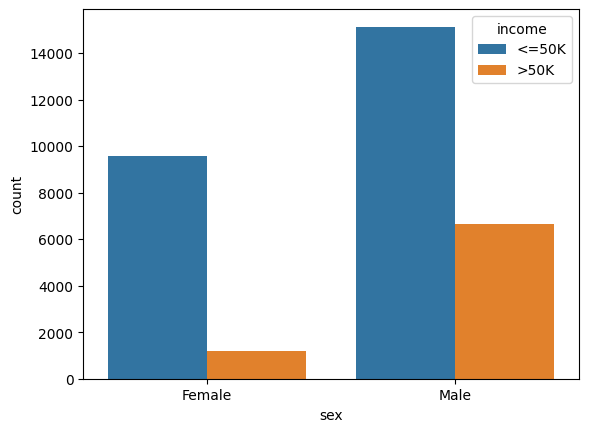

In [97]:
sns.countplot(data=df, x='sex', hue='income')

In [98]:
df.drop(['fnlwgt','education'],axis=1,inplace=True)

In [99]:
for i in df.select_dtypes(include='object'):
  print(i,df[i].nunique())

workclass 8
marital.status 7
occupation 14
relationship 6
race 5
sex 2
native.country 41
income 2


In [100]:
col = ['workclass','marital.status','occupation','race','sex','relationship']
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
for i in col:
  ohe_encoded = ohe.fit_transform(df[[i]]).toarray()
  ohe_df = pd.DataFrame(ohe_encoded,columns=ohe.get_feature_names_out([i]),index=df.index)
  df=pd.concat([df,ohe_df],axis=1)
  df.drop(i,axis=1,inplace=True)

In [101]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['native.country']=le.fit_transform(df['native.country'])

In [102]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 49 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   age                                   32561 non-null  int64  
 1   education.num                         32561 non-null  int64  
 2   capital.gain                          32561 non-null  int64  
 3   capital.loss                          32561 non-null  int64  
 4   hours.per.week                        32561 non-null  int64  
 5   native.country                        32561 non-null  int64  
 6   income                                32561 non-null  object 
 7   workclass_Federal-gov                 32561 non-null  float64
 8   workclass_Local-gov                   32561 non-null  float64
 9   workclass_Never-worked                32561 non-null  float64
 10  workclass_Private                     32561 non-null  float64
 11  workclass_Self-

In [103]:
X = df.drop('income', axis=1)
y = df['income']

In [104]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=100,stratify=None)

In [105]:
num_cols=['capital.gain','capital.loss','hours.per.week']

In [106]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

X_train[num_cols] = sc.fit_transform(X_train[num_cols])
X_test[num_cols] = sc.transform(X_test[num_cols])

In [107]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,precision_score,recall_score,confusion_matrix,classification_report

results=[]

model = LogisticRegression()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

results.append({
    'Method' : 'Normal Data',
    'Accuracy' : accuracy_score(y_test,y_pred),
    # 'precision' : precision_score(y_test,y_pred),
    # 'recall' : recall_score(y_test,y_pred),
    # 'f1_score' : f1_score(y_test,y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [108]:
!pip install imblearn
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote,y_train_smote = smote.fit_resample(X_train,y_train)
print('x_train_smote = ',X_train_smote.shape,'y_train_smote = ',y_train_smote.shape)

x_train_smote =  (39600, 48) y_train_smote =  (39600,)


In [109]:
y_train_smote.value_counts()

,count
income,
<=50K,19800
>50K,19800


In [110]:
model = LogisticRegression(class_weight='balanced')
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

results.append({
    'Method':'Class Weight Balancing',
    'Accuracy' : accuracy_score(y_test,y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [111]:
model = LogisticRegression(class_weight={'<=50K': 1, '>50K': 10})
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced Custom",
    'Accuracy': accuracy_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [112]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy
Method,
Normal Data,0.849225
Class Weight Balancing,0.810072
Class Weight Balanced Custom,0.709504


In [113]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

results=[]
model = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=1)

model.fit(X_train, y_train)
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

Acc_train = accuracy_score(y_train, y_pred_train)
Acc_test = accuracy_score(y_test, y_pred_test)





In [114]:
print('Accuracy train :',Acc_train,'Accuracy test :',Acc_test)



Accuracy train : 0.8739250614250614 Accuracy test : 0.8237371411024106


In [115]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

       <=50K       0.98      0.63      0.77      4920
        >50K       0.46      0.96      0.62      1593

    accuracy                           0.71      6513
   macro avg       0.72      0.79      0.69      6513
weighted avg       0.85      0.71      0.73      6513



In [116]:
from sklearn.naive_bayes import GaussianNB

In [118]:
models = GaussianNB()

models.fit(X_train, y_train)
y_pred_train = models.predict(X_train)
y_pred_test = models.predict(X_test)

Acc_Train = accuracy_score(y_train, y_pred_train)
Acc_Test  =  accuracy_score(y_test, y_pred_test)

print(f"Train Accuracy: {Acc_Train}")
print(f"Test Accuracy: {Acc_Test}\n")
print(classification_report(y_test, y_pred_test))

Train Accuracy: 0.6936808968058968
Test Accuracy: 0.701673575925073

              precision    recall  f1-score   support

       <=50K       0.96      0.63      0.76      4920
        >50K       0.45      0.92      0.60      1593

    accuracy                           0.70      6513
   macro avg       0.70      0.78      0.68      6513
weighted avg       0.84      0.70      0.72      6513



In [119]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[4600  320]
 [ 647  946]]


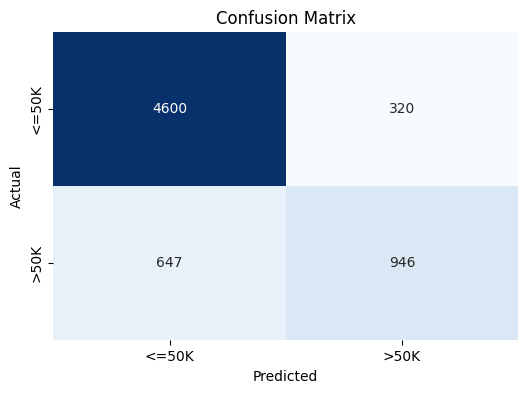


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      4920
        >50K       0.75      0.59      0.66      1593

    accuracy                           0.85      6513
   macro avg       0.81      0.76      0.78      6513
weighted avg       0.85      0.85      0.85      6513

ROC-AUC: 0.9070405202639596


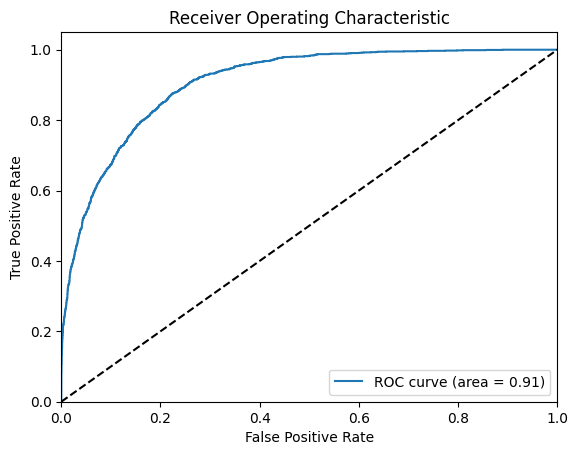

PR AUC: 0.7722007465177231


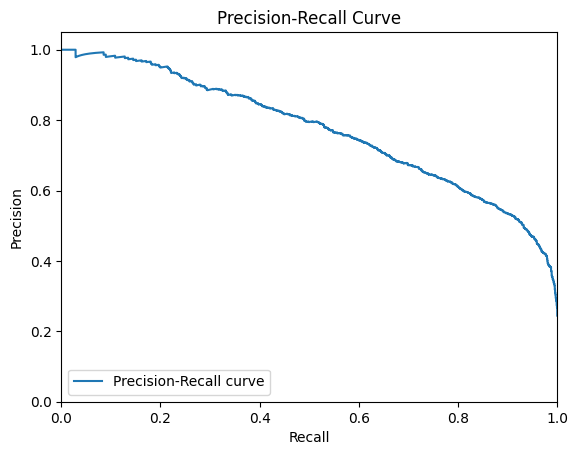

  8%|▊         | 1/13 [00:22<04:32, 22.73s/it]


Confusion Matrix:
 [[4454  466]
 [ 676  917]]


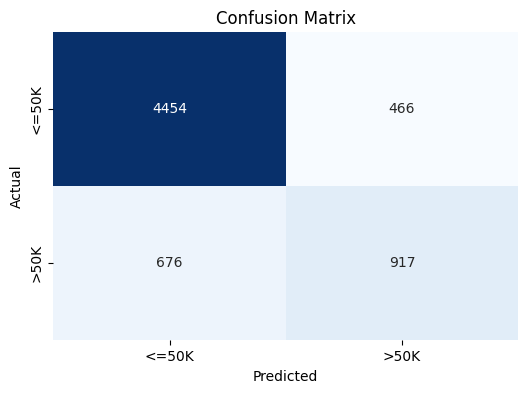


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.87      0.91      0.89      4920
        >50K       0.66      0.58      0.62      1593

    accuracy                           0.82      6513
   macro avg       0.77      0.74      0.75      6513
weighted avg       0.82      0.82      0.82      6513

ROC-AUC: 0.8522490417936195


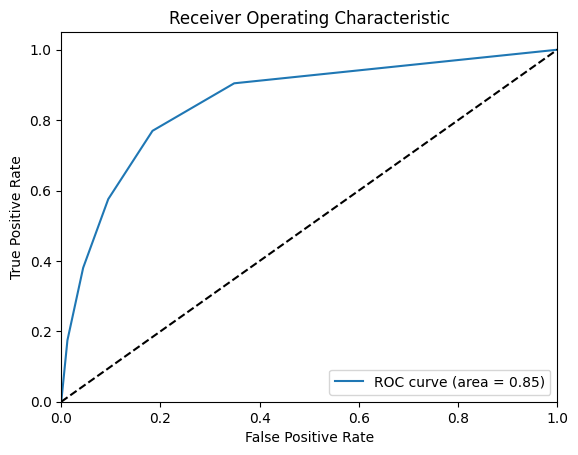

PR AUC: 0.6207275381906302


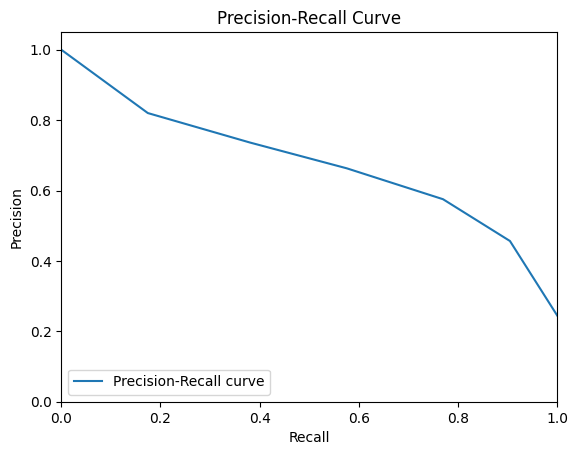

 15%|█▌        | 2/13 [00:32<02:46, 15.18s/it]


Confusion Matrix:
 [[4728  192]
 [ 851  742]]


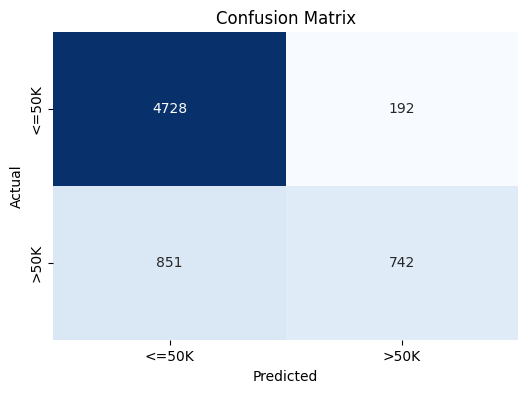


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.85      0.96      0.90      4920
        >50K       0.79      0.47      0.59      1593

    accuracy                           0.84      6513
   macro avg       0.82      0.71      0.74      6513
weighted avg       0.83      0.84      0.82      6513

ROC-AUC: 0.8945774577802275


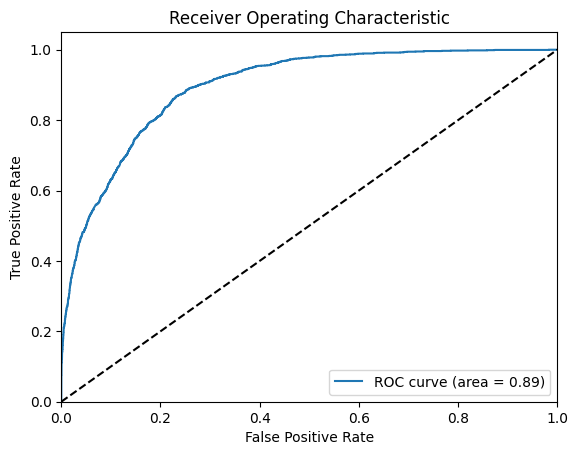

PR AUC: 0.7472137787429459


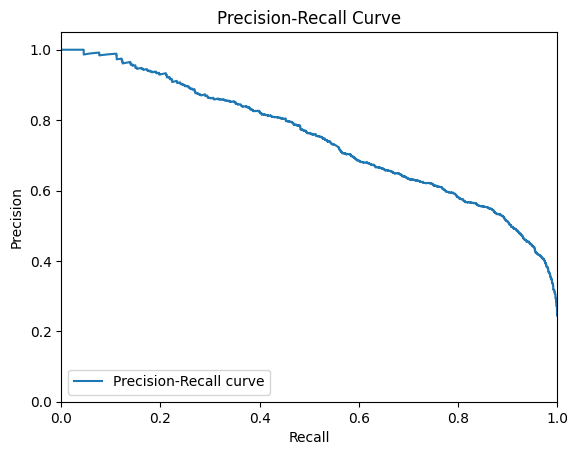

 23%|██▎       | 3/13 [03:38<15:29, 92.97s/it]


Confusion Matrix:
 [[4379  541]
 [ 600  993]]


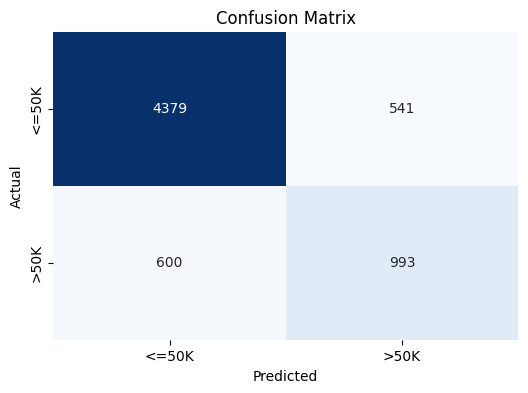


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.89      0.88      4920
        >50K       0.65      0.62      0.64      1593

    accuracy                           0.82      6513
   macro avg       0.76      0.76      0.76      6513
weighted avg       0.82      0.82      0.82      6513

ROC-AUC: 0.780601488218272


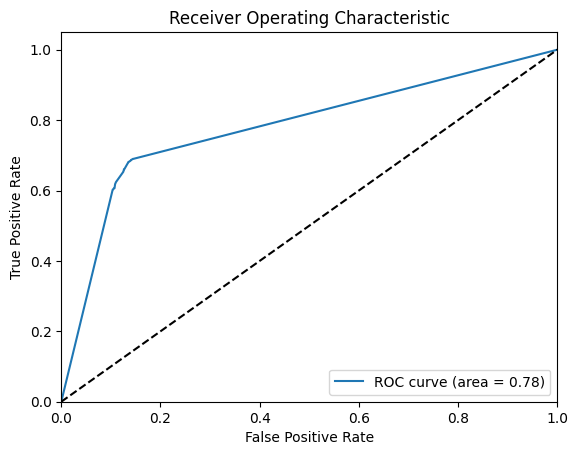

PR AUC: 0.5245622149760671


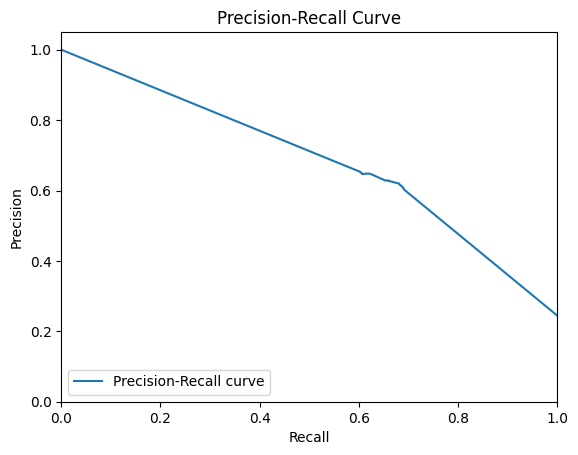

 31%|███       | 4/13 [03:39<08:30, 56.77s/it]


Confusion Matrix:
 [[3102 1818]
 [ 125 1468]]


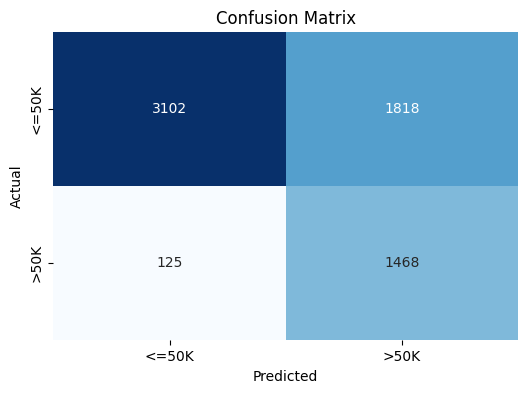


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.96      0.63      0.76      4920
        >50K       0.45      0.92      0.60      1593

    accuracy                           0.70      6513
   macro avg       0.70      0.78      0.68      6513
weighted avg       0.84      0.70      0.72      6513

ROC-AUC: 0.8763397026625632


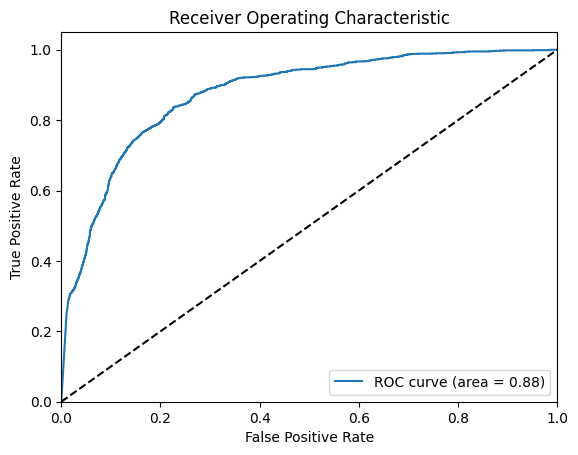

PR AUC: 0.702681746776242


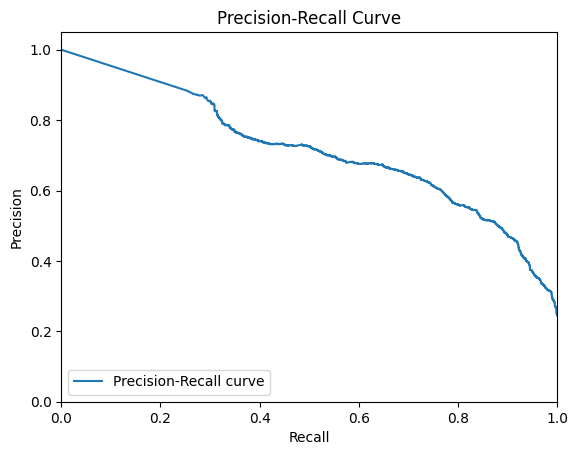

 38%|███▊      | 5/13 [03:40<04:53, 36.68s/it]


Confusion Matrix:
 [[4557  363]
 [ 614  979]]


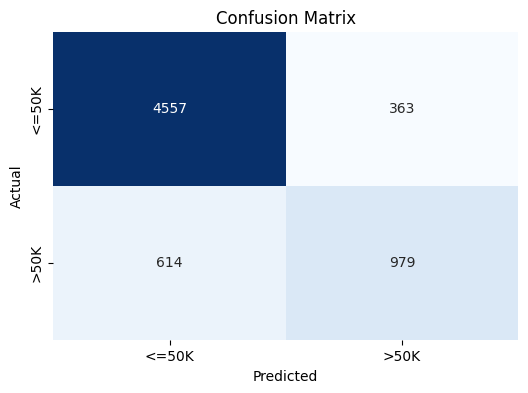


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      4920
        >50K       0.73      0.61      0.67      1593

    accuracy                           0.85      6513
   macro avg       0.81      0.77      0.79      6513
weighted avg       0.84      0.85      0.85      6513

ROC-AUC: 0.9002287701784739


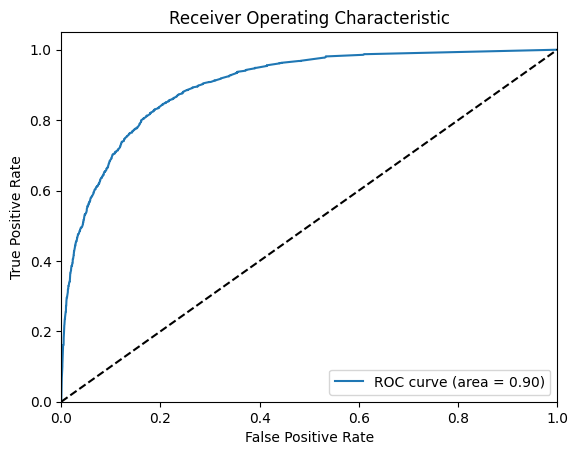

PR AUC: 0.7590793659848925


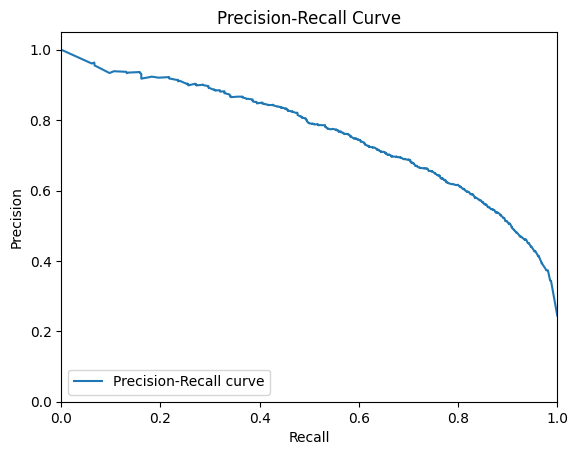

 46%|████▌     | 6/13 [03:45<03:01, 25.88s/it]


Confusion Matrix:
 [[4497  423]
 [ 655  938]]


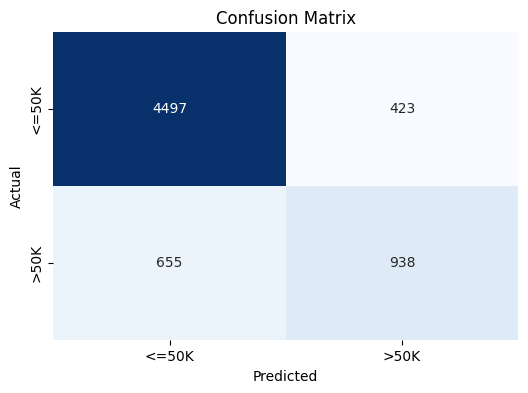


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.87      0.91      0.89      4920
        >50K       0.69      0.59      0.64      1593

    accuracy                           0.83      6513
   macro avg       0.78      0.75      0.76      6513
weighted avg       0.83      0.83      0.83      6513

ROC-AUC: 0.8611716529123861


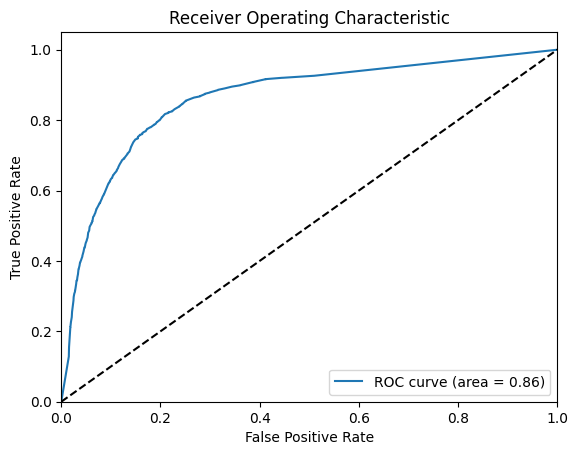

PR AUC: 0.6585475291020155


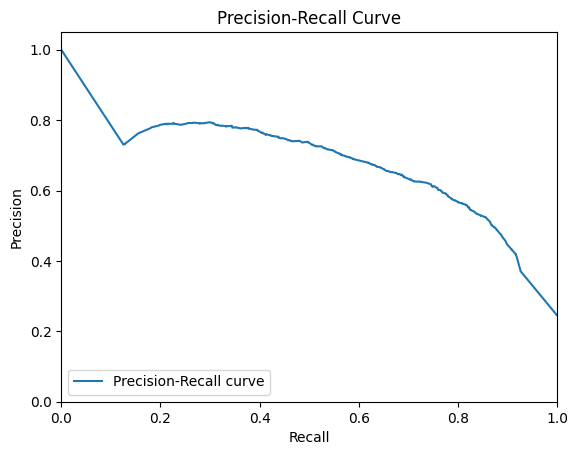

 54%|█████▍    | 7/13 [03:52<01:58, 19.70s/it]


Confusion Matrix:
 [[4665  255]
 [ 719  874]]


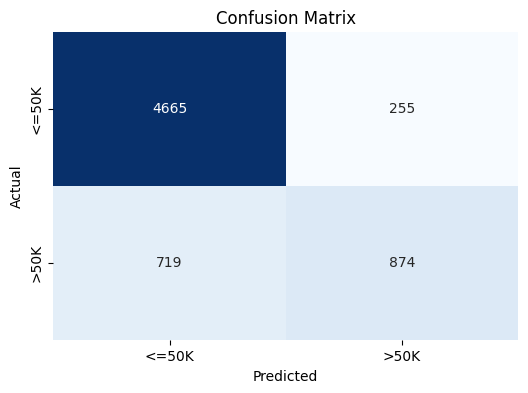


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.87      0.95      0.91      4920
        >50K       0.77      0.55      0.64      1593

    accuracy                           0.85      6513
   macro avg       0.82      0.75      0.77      6513
weighted avg       0.84      0.85      0.84      6513

ROC-AUC: 0.9055024778119721


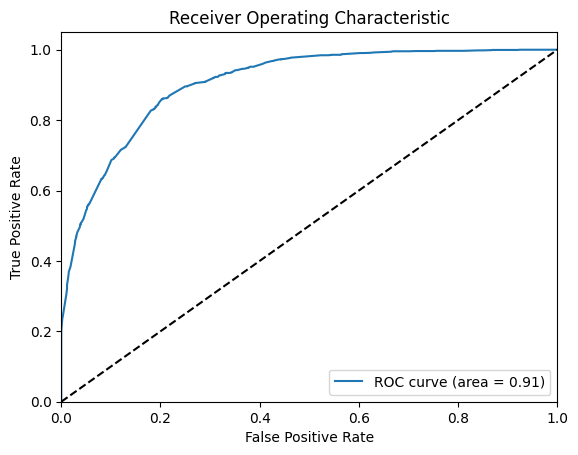

PR AUC: 0.7729816728879018


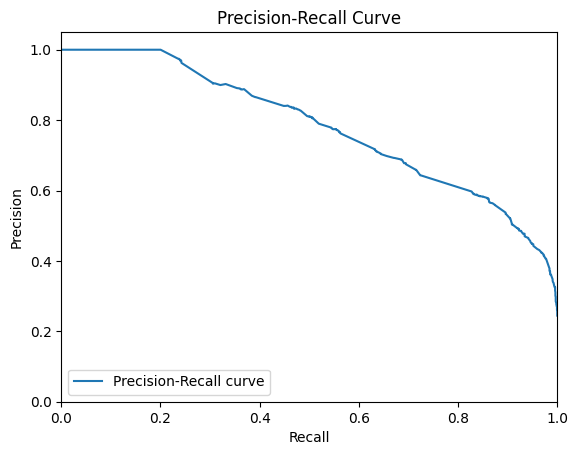

 62%|██████▏   | 8/13 [03:56<01:13, 14.61s/it]


Confusion Matrix:
 [[4686  234]
 [ 638  955]]


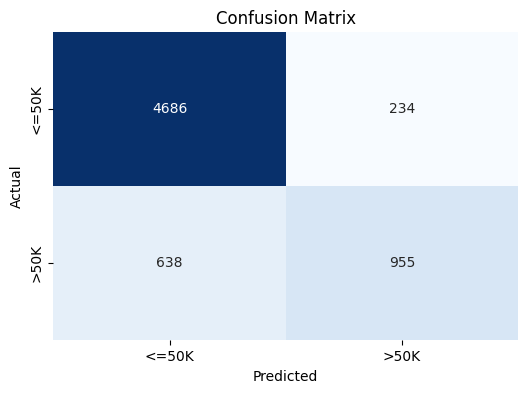


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      4920
        >50K       0.80      0.60      0.69      1593

    accuracy                           0.87      6513
   macro avg       0.84      0.78      0.80      6513
weighted avg       0.86      0.87      0.86      6513

ROC-AUC: 0.9241902454335278


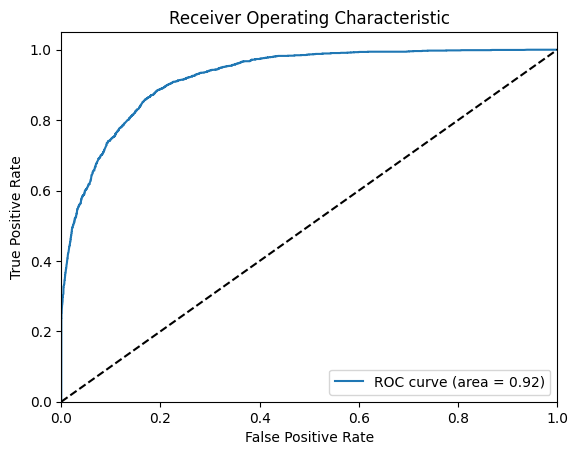

PR AUC: 0.8228202503576055


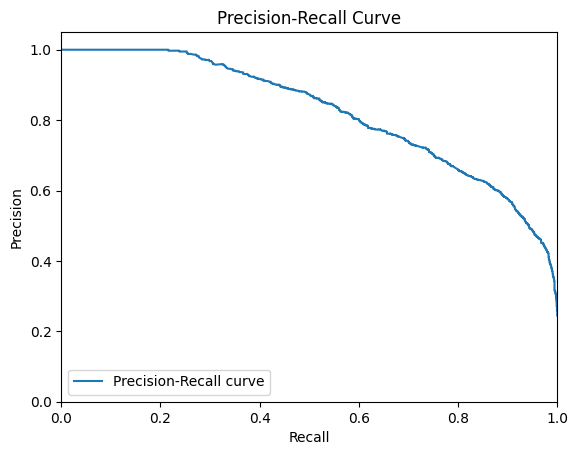

 69%|██████▉   | 9/13 [04:01<00:46, 11.58s/it]


Confusion Matrix:
 [[4612  308]
 [ 539 1054]]


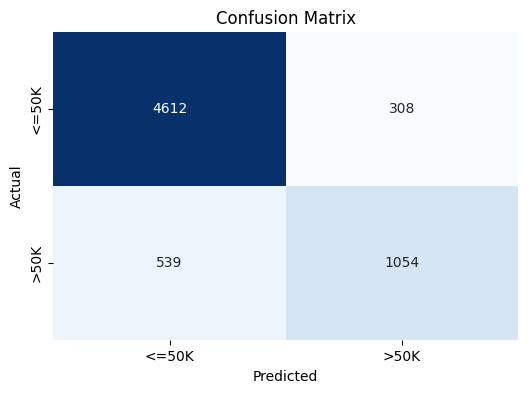


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      4920
        >50K       0.77      0.66      0.71      1593

    accuracy                           0.87      6513
   macro avg       0.83      0.80      0.81      6513
weighted avg       0.87      0.87      0.87      6513

ROC-AUC: 0.9292773516247403


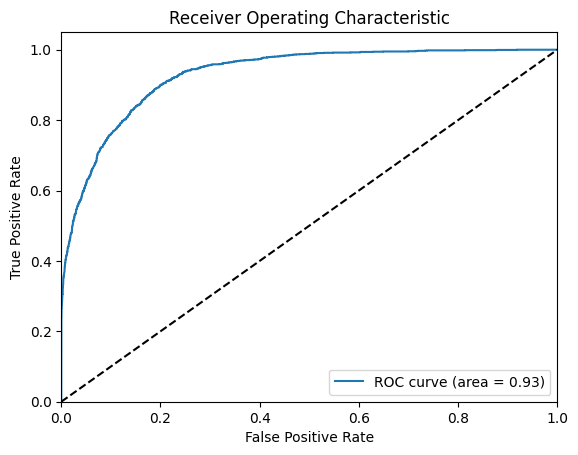

PR AUC: 0.8331515456416658


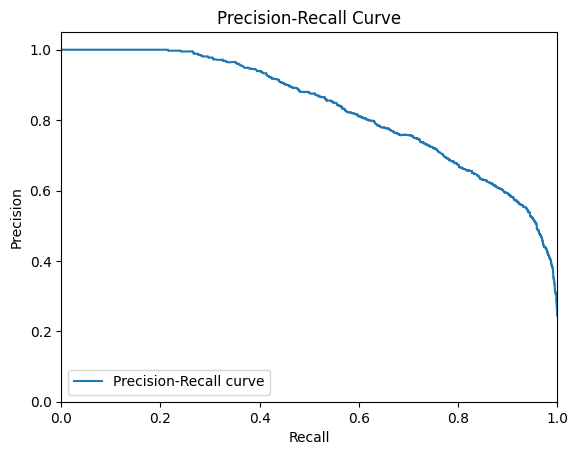

 77%|███████▋  | 10/13 [04:05<01:13, 24.55s/it]


ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1], got ['<=50K' '>50K']

In [121]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['<=50K','>50K']
                ,yticklabels=['<=50K','>50K'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['<=50K','>50K'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label='>50K')
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test == '>50K', y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test == '>50K', y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred, pos_label='>50K'),
        "Test Precision": precision_score(y_test, test_pred, pos_label='>50K'),
        "Train Recall": recall_score(y_train, train_pred, pos_label='>50K'),
        "Test Recall": recall_score(y_test, test_pred, pos_label='>50K'),
        "Train F1 Score": f1_score(y_train, train_pred, pos_label='>50K'),
        "Test F1 Score": f1_score(y_test, test_pred, pos_label='>50K'),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc
    }

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:06:02] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4340  580]
 [ 349 1244]]


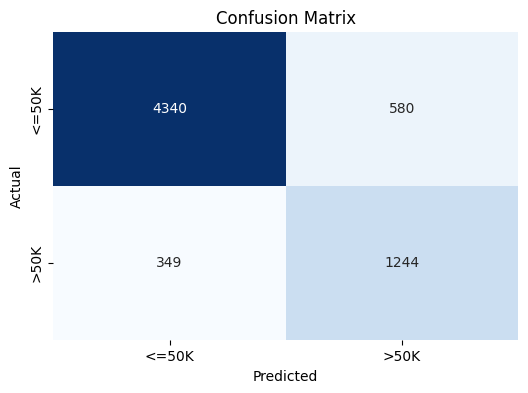


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.93      0.88      0.90      4920
        >50K       0.68      0.78      0.73      1593

    accuracy                           0.86      6513
   macro avg       0.80      0.83      0.82      6513
weighted avg       0.87      0.86      0.86      6513

ROC-AUC: 0.9180953638632431


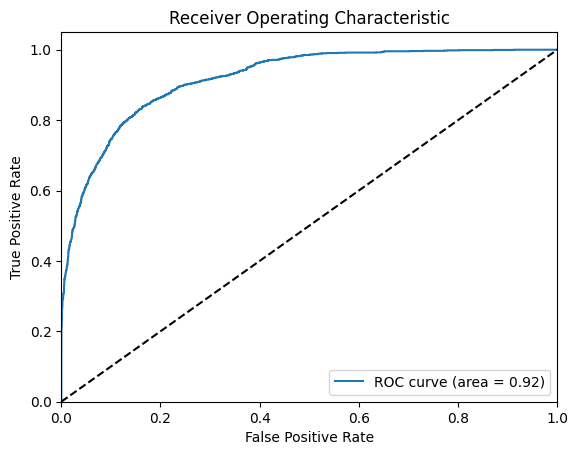

PR AUC: 0.8159283804243711


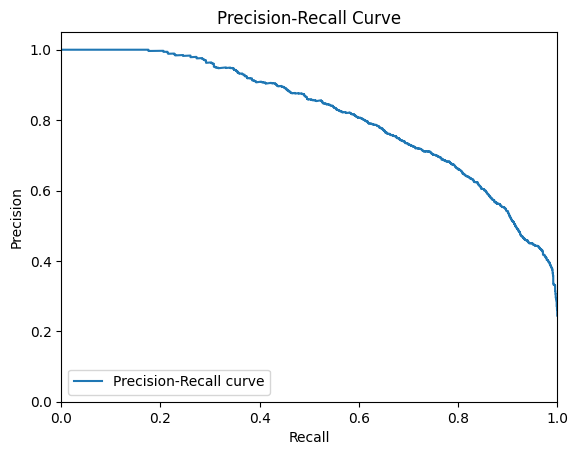

In [122]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft"
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)

cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['<=50K','>50K']
            ,yticklabels=['<=50K','>50K'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['<=50K','>50K'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label='>50K')
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test == '>50K', y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test == '>50K', y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred, pos_label='>50K'),
    "Test Precision": precision_score(y_test, voting_test_pred, pos_label='>50K'),
    "Train Recall": recall_score(y_train, voting_train_pred, pos_label='>50K'),
    "Test Recall": recall_score(y_test, voting_test_pred, pos_label='>50K'),
    "Train F1 Score": f1_score(y_train, voting_train_pred, pos_label='>50K'),
    "Test F1 Score": f1_score(y_test, voting_test_pred, pos_label='>50K'),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}


Confusion Matrix:
 [[4591  329]
 [ 534 1059]]


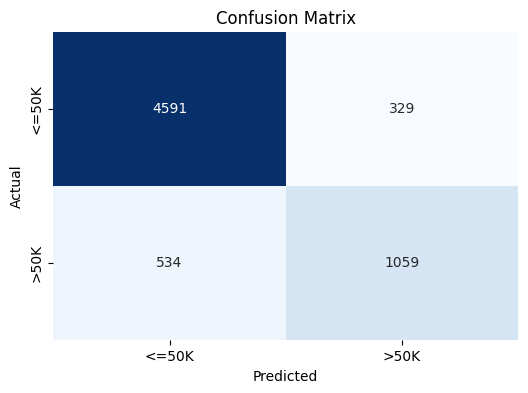


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.90      0.93      0.91      4920
        >50K       0.76      0.66      0.71      1593

    accuracy                           0.87      6513
   macro avg       0.83      0.80      0.81      6513
weighted avg       0.86      0.87      0.86      6513

ROC-AUC: 0.9226507994835127


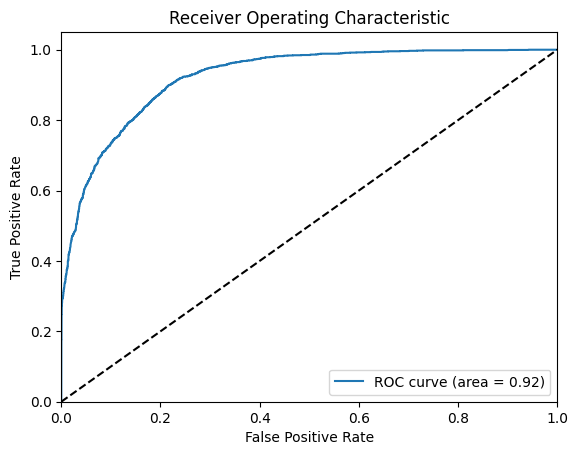

PR AUC: 0.8175701075531314


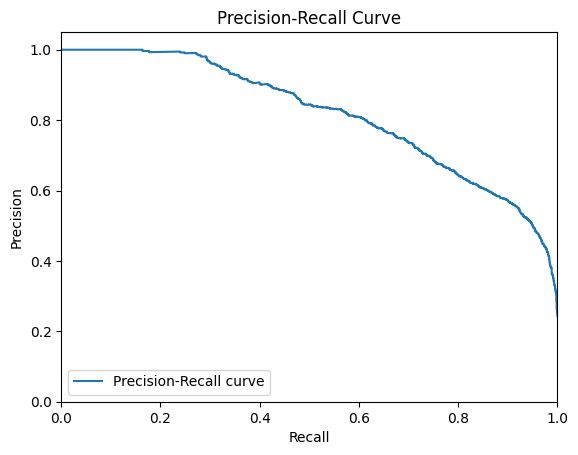

In [123]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),
    ],
    final_estimator=XGBClassifier(eval_metric='logloss', random_state=1),
    stack_method="predict_proba",
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['<=50K','>50K']
            ,yticklabels=['<=50K','>50K'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['<=50K','>50K'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label='>50K')
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test == '>50K', y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test == '>50K', y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred, pos_label='>50K'),
    "Test Precision": precision_score(y_test, stack_auto_test_pred, pos_label='>50K'),
    "Train Recall": recall_score(y_train, stack_auto_train_pred, pos_label='>50K'),
    "Test Recall": recall_score(y_test, stack_auto_test_pred, pos_label='>50K'),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred, pos_label='>50K'),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred, pos_label='>50K'),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [124]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [125]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Voting Classifier,0.910012,0.857362,0.775007,0.682018,0.880442,0.780917,0.824367,0.728124,0.899893,0.831515,0.918095,0.815928
Hist Gradient Boosting,0.886748,0.869952,0.807764,0.773862,0.692702,0.661645,0.745821,0.713367,0.820341,0.799522,0.929277,0.833152
Stacking Classifier,0.882947,0.867496,0.797029,0.762968,0.686940,0.664783,0.737901,0.710500,0.815869,0.798957,0.922651,0.817570
Gradient Boosting,0.868205,0.866114,0.795631,0.803196,0.606274,0.599498,0.688164,0.686556,0.778566,0.775968,0.924190,0.822820
Random Forest,0.978501,0.849992,0.966382,0.729508,0.943182,0.614564,0.954641,0.667121,0.966414,0.770392,0.900229,0.759079
Logistic Regression,0.850392,0.851528,0.731808,0.747235,0.593950,0.593848,0.655712,0.661770,0.762632,0.764404,0.907041,0.772201
AdaBoost,0.852196,0.850453,0.766208,0.774136,0.552337,0.548650,0.641927,0.642175,0.749577,0.748411,0.905502,0.772982
Decision Tree,0.978501,0.824812,0.986820,0.647327,0.922695,0.623352,0.953681,0.635114,0.959403,0.756696,0.780601,0.524562
Extra Trees,0.978501,0.834485,0.986820,0.689199,0.922695,0.588826,0.953681,0.635071,0.959403,0.751425,0.861172,0.658548
KNN,0.875038,0.824658,0.768720,0.663051,0.685179,0.575643,0.724549,0.616263,0.810064,0.740464,0.852249,0.620728


<Axes: >

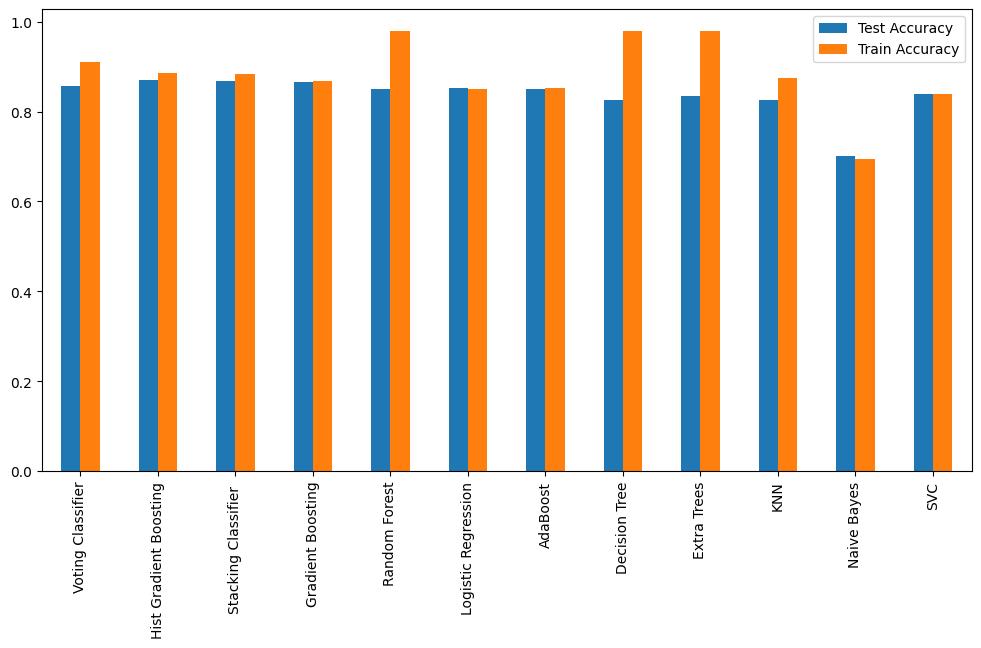

In [126]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

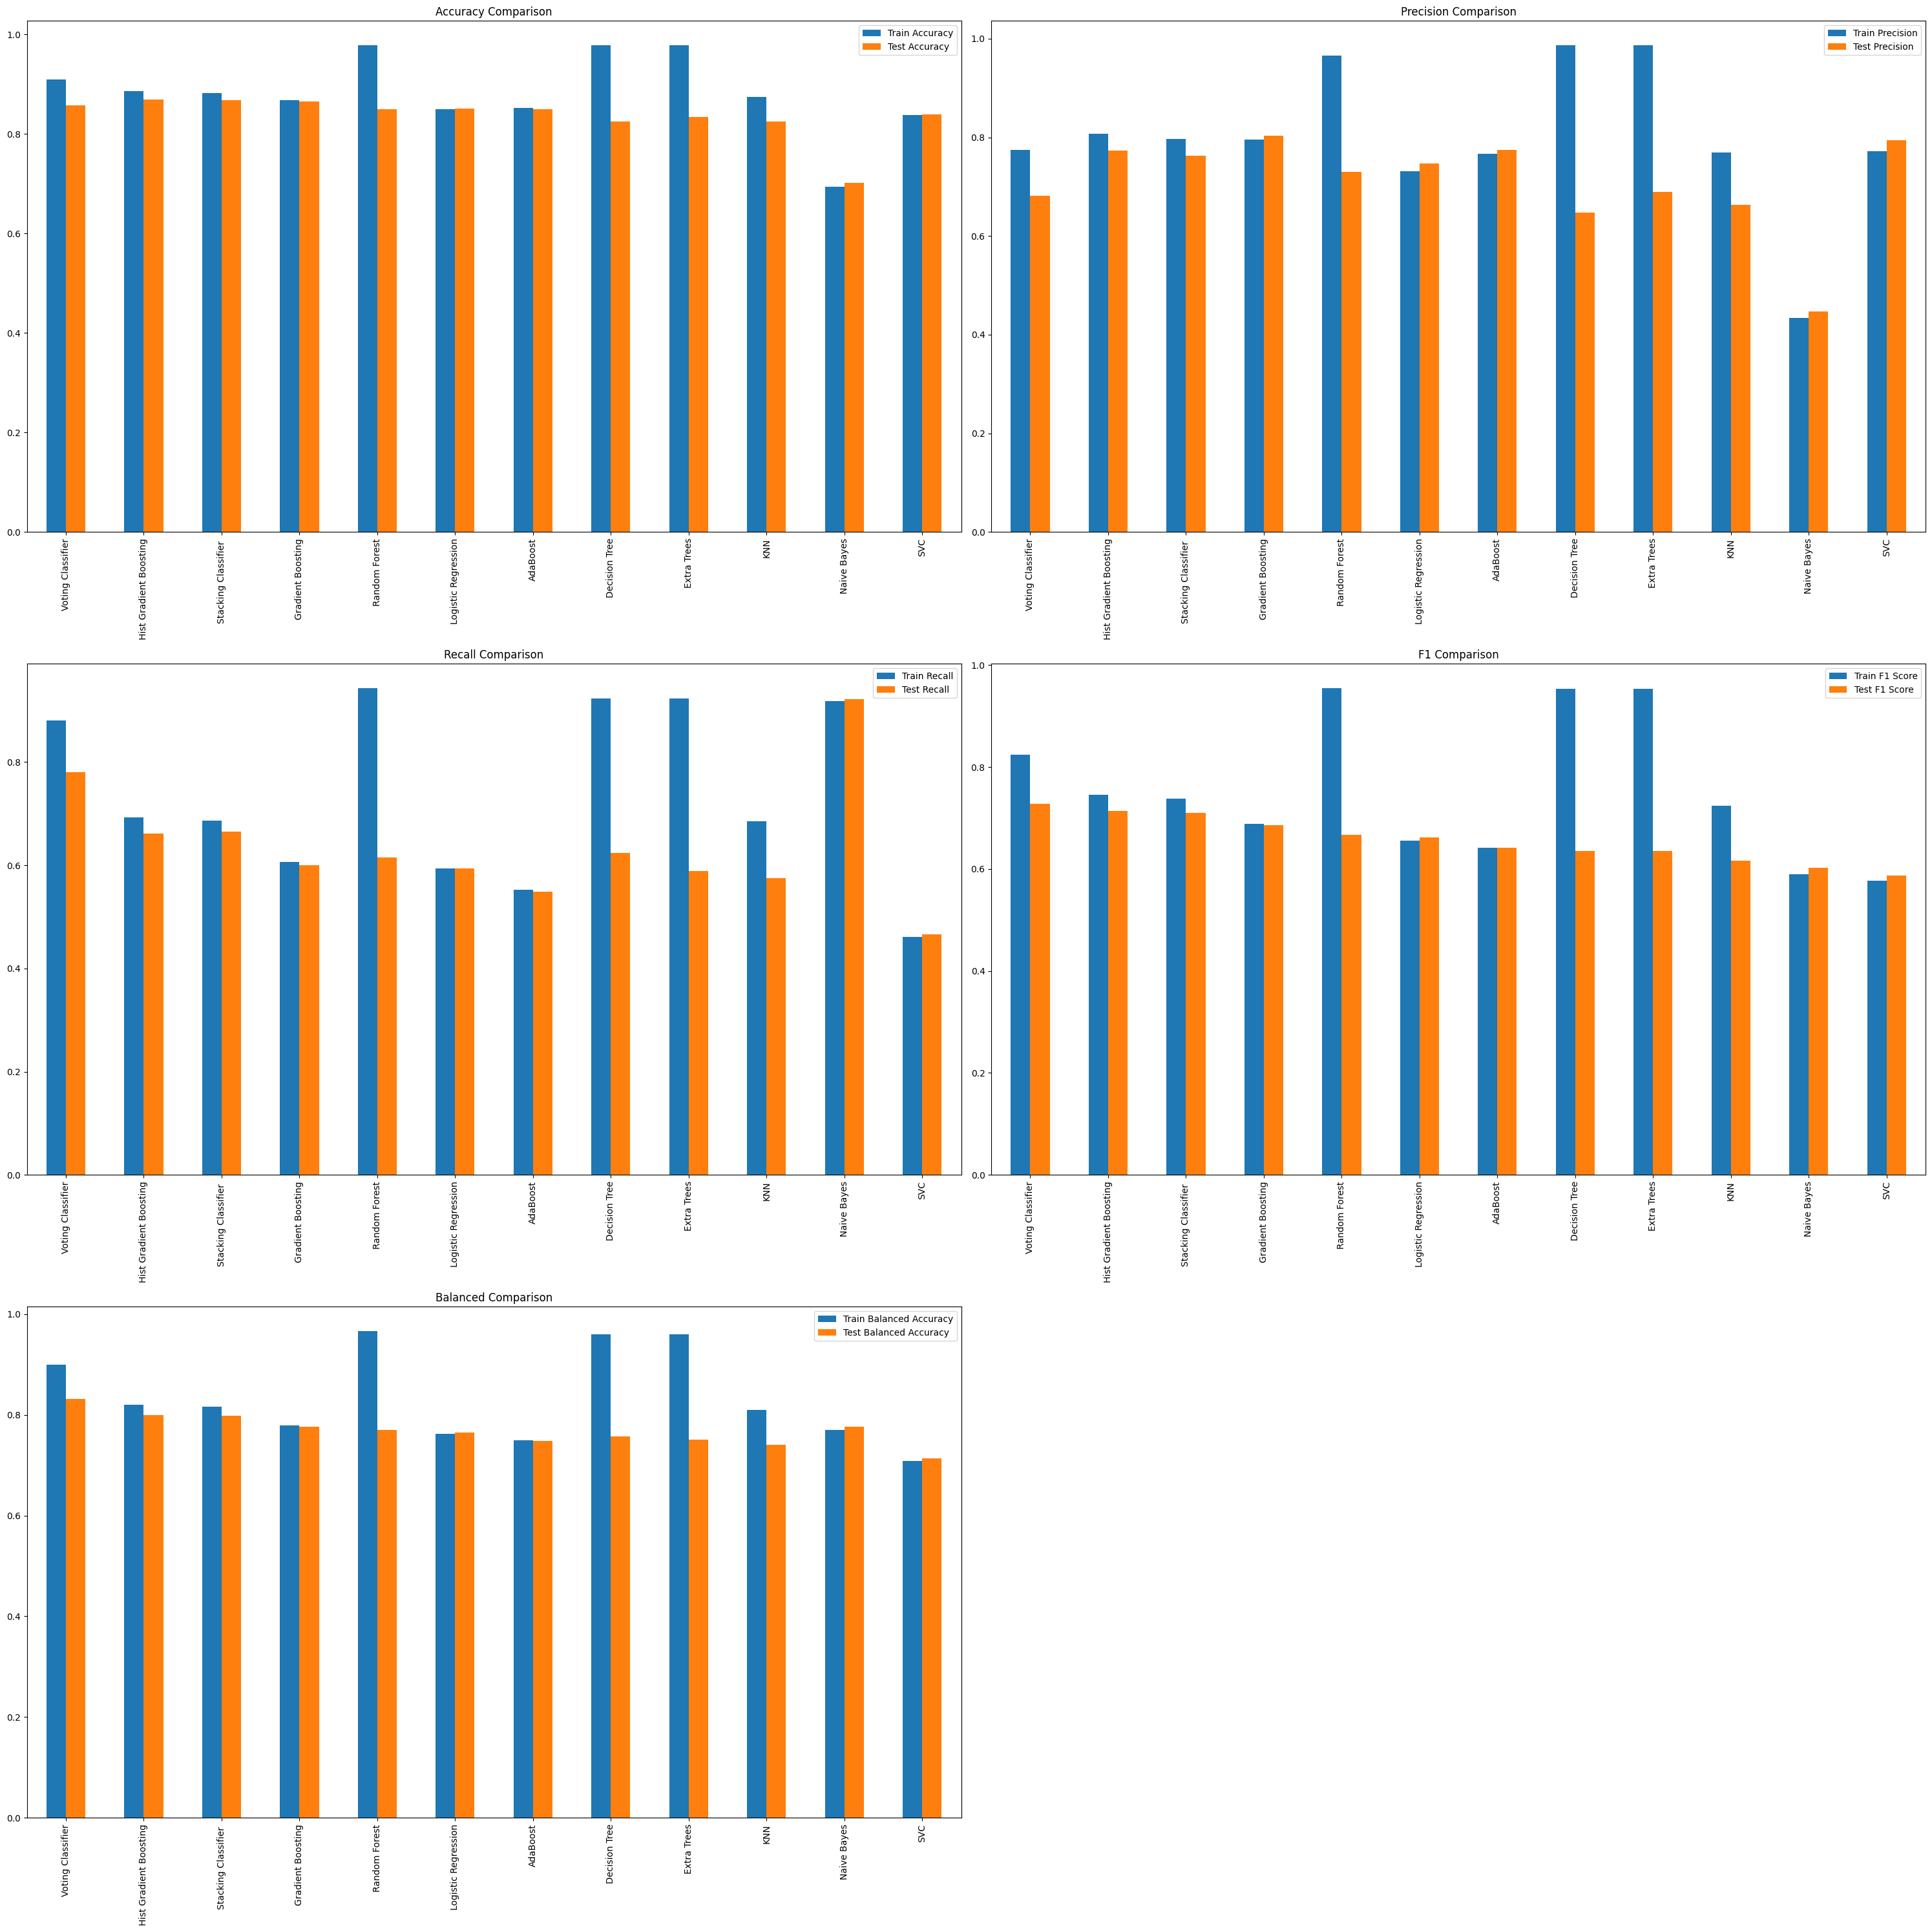

In [127]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()